In [5]:
# Libraries install karne ke liye (agar installed nahi hain):
# !pip install pandas numpy matplotlib seaborn openpyxl sqlite3

import os
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Plot styling configuration
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 10


In [7]:
# Dataset load karein
input_filename = 'ecommerce_sales_customer_analysis.xlsx'

xls = pd.ExcelFile(input_filename)
print("Available Sheets:", xls.sheet_names)

# Primary Orders sheet ko DataFrame me load karein
df_raw = pd.read_excel(input_filename, sheet_name='Orders')
print(f"Total Rows: {df_raw.shape[0]}, Total Columns: {df_raw.shape[1]}")
df_raw.head()

Available Sheets: ['Orders', 'Category_Summary', 'Region_Summary', 'Top_Customers']
Total Rows: 5000, Total Columns: 22


,Order_ID,Order_Date,Customer_ID,Product_ID,Category,Sub_Category,Product_Name,Quantity,Unit_Price,Discount,...,Payment_Mode,City,State,Region,Customer_Type,Shipping_Days,Year,Month,Month_Name,Profit_Margin
0,ORD100001,2025-04-13,CUST1088,P1011,Fashion,Women,Kurti Set,1,5691,0.05,...,Net Banking,Patna,Bihar,East,Returning,1,2025,4,Apr,8.81
1,ORD100002,2025-05-11,CUST1748,P1012,Fashion,Women,Handbag,1,2933,0.05,...,UPI,Agra,Uttar Pradesh,North,New,3,2025,5,May,11.48
2,ORD100003,2025-02-28,CUST1567,P1012,Fashion,Women,Handbag,1,3247,0.10,...,Cash on Delivery,Mysuru,Karnataka,South,Returning,2,2025,2,Feb,20.13
3,ORD100004,2025-05-11,CUST1346,P1007,Home & Kitchen,Kitchen,Mixer Grinder,1,15302,0.20,...,Net Banking,Jaipur,Rajasthan,North,New,3,2025,5,May,16.14
4,ORD100005,2025-04-02,CUST1562,P1012,Fashion,Women,Handbag,1,1978,0.15,...,Cash on Delivery,Patna,Bihar,East,New,3,2025,4,Apr,9.12


In [8]:
# 1. Missing Values & Duplicate check
print("Missing values per column:\n", df_raw.isnull().sum())
print(f"Duplicate Order_IDs: {df_raw['Order_ID'].duplicated().sum()}")

# 2. String trimming (extra spaces remove karna)
df_clean = df_raw.copy()
text_columns = df_clean.select_dtypes(include='object').columns
for col in text_columns:
    df_clean[col] = df_clean[col].astype(str).str.strip()

# 3. Standardize Dates
df_clean['Order_Date'] = pd.to_datetime(df_clean['Order_Date'])
df_clean['Year'] = df_clean['Order_Date'].dt.year
df_clean['Month'] = df_clean['Order_Date'].dt.month
df_clean['Month_Name'] = df_clean['Order_Date'].dt.strftime('%b')

# 4. Mathematical validation (Sales = Quantity * Unit_Price * (1 - Discount))
calculated_sales = (df_clean['Quantity'] * df_clean['Unit_Price'] * (1 - df_clean['Discount'])).round(2)
sales_mismatch = (df_clean['Sales'].round(2) != calculated_sales).sum()

calculated_margin = ((df_clean['Profit'] / df_clean['Sales']) * 100).round(2)
margin_mismatch = (df_clean['Profit_Margin'].round(2) != calculated_margin).sum()

print(f"Sales formula discrepancies: {sales_mismatch}")
print(f"Profit margin formula discrepancies: {margin_mismatch}")
print("Data Validation Status: 100% Validated & Cleaned!")

Missing values per column:
 Order_ID         0
Order_Date       0
Customer_ID      0
Product_ID       0
Category         0
Sub_Category     0
Product_Name     0
Quantity         0
Unit_Price       0
Discount         0
Sales            0
Profit           0
Payment_Mode     0
City             0
State            0
Region           0
Customer_Type    0
Shipping_Days    0
Year             0
Month            0
Month_Name       0
Profit_Margin    0
dtype: int64
Duplicate Order_IDs: 0


C:\Users\prate\AppData\Local\Temp\ipykernel_10948\553049416.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  text_columns = df_clean.select_dtypes(include='object').columns


Sales formula discrepancies: 0
Profit margin formula discrepancies: 0
Data Validation Status: 100% Validated & Cleaned!


In [9]:
# High-Level Business Metrics
total_revenue = df_clean['Sales'].sum()
total_profit = df_clean['Profit'].sum()
overall_margin = (total_profit / total_revenue) * 100
total_orders = df_clean['Order_ID'].nunique()
unique_customers = df_clean['Customer_ID'].nunique()
aov = total_revenue / total_orders

print("=" * 45)
print(f"Total Revenue:       ₹{total_revenue:,.2f}")
print(f"Total Net Profit:    ₹{total_profit:,.2f}")
print(f"Overall Margin:      {overall_margin:.2f}%")
print(f"Total Orders:        {total_orders:,}")
print(f"Unique Customers:    {unique_customers:,}")
print(f"Average Order Value: ₹{aov:,.2f}")
print("=" * 45)

Total Revenue:       ₹90,612,975.10
Total Net Profit:    ₹13,659,233.93
Overall Margin:      15.07%
Total Orders:        5,000
Unique Customers:    995
Average Order Value: ₹18,122.60


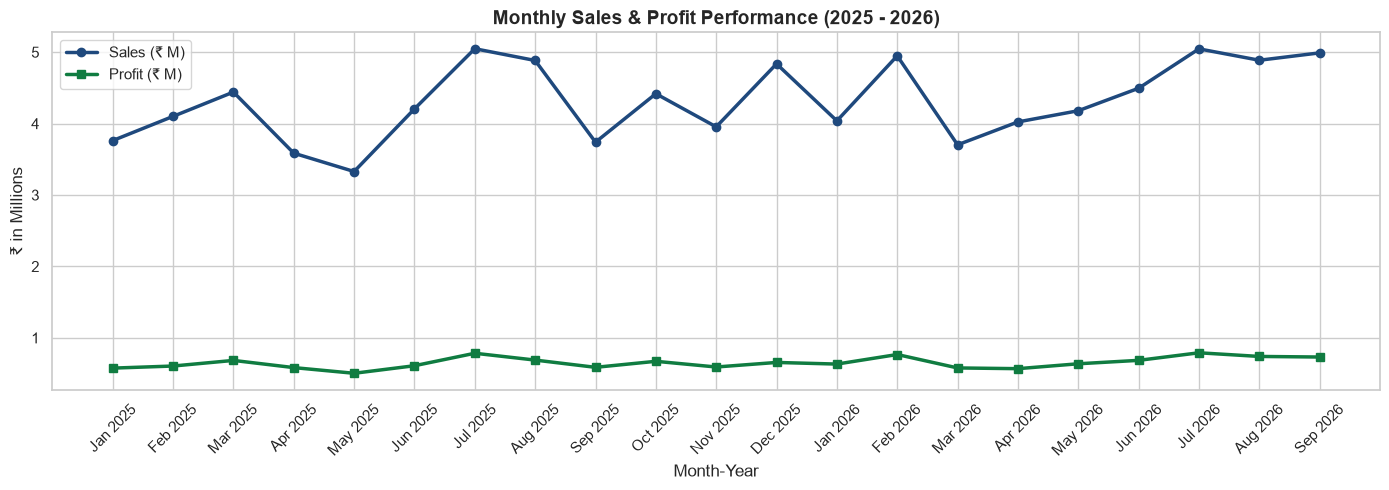

C:\Users\prate\AppData\Local\Temp\ipykernel_10948\4260353007.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_clean, x='Region', y='Sales', estimator=sum, errorbar=None, palette='crest', ax=axes[1])


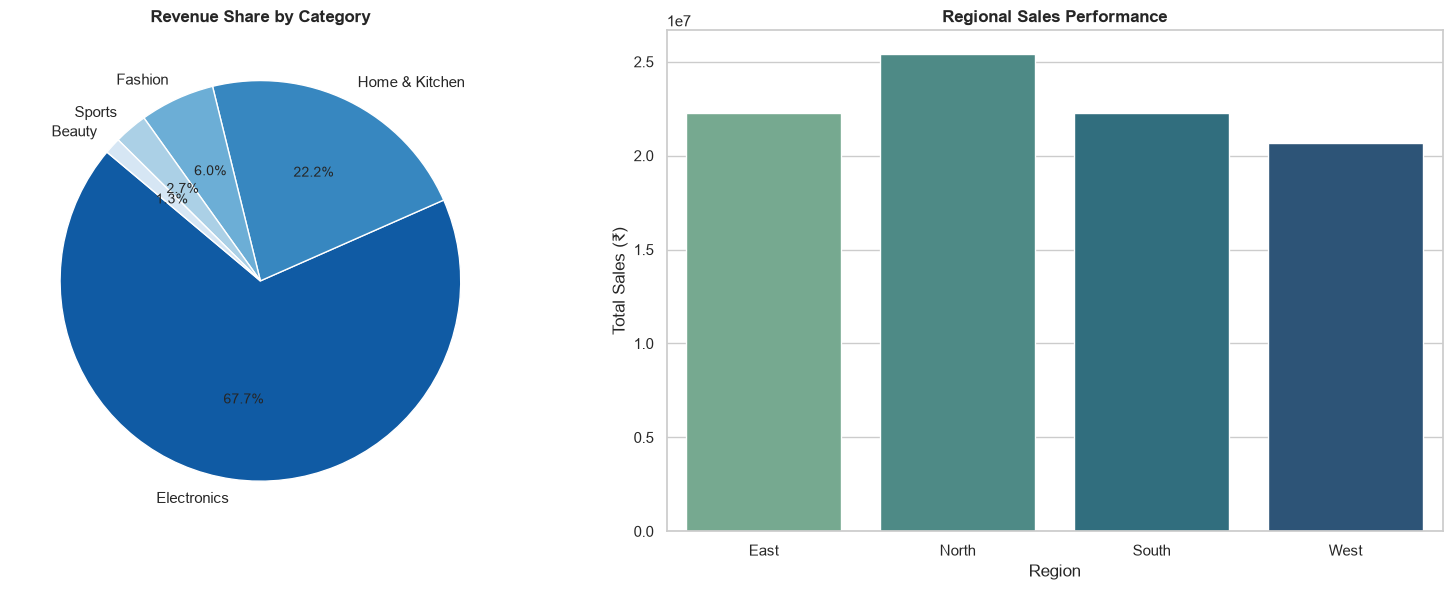

In [10]:
# Chart 1: Monthly Revenue & Profit Trend
monthly_trend = df_clean.groupby(['Year', 'Month', 'Month_Name'], as_index=False).agg({
    'Sales': 'sum',
    'Profit': 'sum'
})
monthly_trend['Period'] = monthly_trend['Month_Name'] + " " + monthly_trend['Year'].astype(str)

plt.figure(figsize=(14, 5))
plt.plot(monthly_trend['Period'], monthly_trend['Sales'] / 1e6, marker='o', color='#1F497D', linewidth=2.5, label='Sales (₹ M)')
plt.plot(monthly_trend['Period'], monthly_trend['Profit'] / 1e6, marker='s', color='#107C41', linewidth=2.5, label='Profit (₹ M)')
plt.title('Monthly Sales & Profit Performance (2025 - 2026)', fontsize=14, fontweight='bold')
plt.xlabel('Month-Year')
plt.ylabel('₹ in Millions')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

# Chart 2: Category Share & Regional Breakdown
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cat_sales = df_clean.groupby('Category')['Sales'].sum().sort_values(ascending=False)
axes[0].pie(cat_sales, labels=cat_sales.index, autopct='%1.1f%%', startangle=140, colors=sns.color_palette('Blues_r', len(cat_sales)))
axes[0].set_title('Revenue Share by Category', fontsize=12, fontweight='bold')

sns.barplot(data=df_clean, x='Region', y='Sales', estimator=sum, errorbar=None, palette='crest', ax=axes[1])
axes[1].set_title('Regional Sales Performance', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Total Sales (₹)')
plt.tight_layout()
plt.show()

In [11]:
# SQLite Database connection create karein
conn = sqlite3.connect('ecommerce_sales.db')
cursor = conn.cursor()

# SQL Table DDL create karein
cursor.execute('''
CREATE TABLE IF NOT EXISTS ecommerce_orders (
    order_id        TEXT PRIMARY KEY,
    order_date      TEXT NOT NULL,
    customer_id     TEXT NOT NULL,
    product_id      TEXT NOT NULL,
    category        TEXT NOT NULL,
    sub_category    TEXT NOT NULL,
    product_name    TEXT NOT NULL,
    quantity        INTEGER NOT NULL,
    unit_price      REAL NOT NULL,
    discount        REAL DEFAULT 0.0,
    sales           REAL NOT NULL,
    profit          REAL NOT NULL,
    payment_mode    TEXT NOT NULL,
    city            TEXT NOT NULL,
    state           TEXT NOT NULL,
    region          TEXT NOT NULL,
    customer_type   TEXT NOT NULL,
    shipping_days   INTEGER NOT NULL,
    order_year      INTEGER NOT NULL,
    order_month     INTEGER NOT NULL,
    month_name      TEXT NOT NULL,
    profit_margin   REAL NOT NULL
);
''')

# Pandas DataFrame ko SQL table format me rename karke load karein
df_sql = df_clean.rename(columns={
    'Order_ID': 'order_id', 'Order_Date': 'order_date', 'Customer_ID': 'customer_id',
    'Product_ID': 'product_id', 'Category': 'category', 'Sub_Category': 'sub_category',
    'Product_Name': 'product_name', 'Quantity': 'quantity', 'Unit_Price': 'unit_price',
    'Discount': 'discount', 'Sales': 'sales', 'Profit': 'profit',
    'Payment_Mode': 'payment_mode', 'City': 'city', 'State': 'state', 'Region': 'region',
    'Customer_Type': 'customer_type', 'Shipping_Days': 'shipping_days', 'Year': 'order_year',
    'Month': 'order_month', 'Month_Name': 'month_name', 'Profit_Margin': 'profit_margin'
})
df_sql['order_date'] = df_sql['order_date'].dt.strftime('%Y-%m-%d')

df_sql.to_sql('ecommerce_orders', conn, if_exists='replace', index=False)
conn.commit()

# Record count verify karein
cursor.execute('SELECT COUNT(*) FROM ecommerce_orders')
print(f"Total Records loaded in SQL Database: {cursor.fetchone()[0]}")

Total Records loaded in SQL Database: 5000


In [12]:
# Query 1: Top 5 Best-Selling Products by Revenue
q1 = '''
SELECT 
    product_name,
    category,
    SUM(quantity) AS units_sold,
    ROUND(SUM(sales), 2) AS total_revenue,
    ROUND(SUM(profit), 2) AS net_profit,
    ROUND((SUM(profit) / SUM(sales)) * 100, 2) AS margin_pct
FROM ecommerce_orders
GROUP BY product_name, category
ORDER BY total_revenue DESC
LIMIT 5;
'''
display(pd.read_sql_query(q1, conn))

# Query 2: Customer Retention Analysis (New vs Returning)
q2 = '''
SELECT 
    customer_type,
    COUNT(DISTINCT customer_id) AS total_customers,
    COUNT(order_id) AS total_orders,
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(AVG(sales), 2) AS avg_order_value,
    ROUND(SUM(profit), 2) AS total_profit
FROM ecommerce_orders
GROUP BY customer_type;
'''
display(pd.read_sql_query(q2, conn))

,product_name,category,units_sold,total_revenue,net_profit,margin_pct
0,Wireless Earbuds,Electronics,488,16891599.30,2617542.62,15.50
1,Power Bank,Electronics,480,15644704.55,2415315.14,15.44
2,Smartphone X,Electronics,443,14787362.35,2077134.96,14.05
3,Laptop Pro 14,Electronics,442,14038939.65,2178421.21,15.52
4,Mixer Grinder,Home & Kitchen,457,5167881.30,774115.58,14.98


,customer_type,total_customers,total_orders,total_sales,avg_order_value,total_profit
0,New,868,2112,38395167.85,18179.53,5746141.87
1,Returning,949,2888,52217807.25,18080.96,7913092.06


In [13]:
output_excel = 'ecommerce_sales_cleaned_formatted.xlsx'

with pd.ExcelWriter(output_excel, engine='openpyxl') as writer:
    # 1. Main Orders Sheet
    df_clean.to_excel(writer, sheet_name='Orders', index=False)
    
    # 2. Category Summary Sheet
    cat_summary = df_clean.groupby('Category').agg(
        Sales=('Sales', 'sum'),
        Profit=('Profit', 'sum'),
        Orders=('Order_ID', 'count')
    ).reset_index()
    cat_summary.to_excel(writer, sheet_name='Category_Summary', index=False)
    
    # 3. Regional Summary Sheet
    reg_summary = df_clean.groupby('Region').agg(
        Sales=('Sales', 'sum'),
        Profit=('Profit', 'sum'),
        Orders=('Order_ID', 'count'),
        Customers=('Customer_ID', 'nunique')
    ).reset_index()
    reg_summary.to_excel(writer, sheet_name='Region_Summary', index=False)

print(f"Cleaned and summary tables exported successfully to: {output_excel}")
conn.close()

Cleaned and summary tables exported successfully to: ecommerce_sales_cleaned_formatted.xlsx
